In [54]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [55]:
sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": "#EAF2F8",
        "axes.facecolor": "#F4F9FD",
        "axes.edgecolor": "#2C52BB",
        "grid.color": "#D6EAF8",
        "axes.titleweight": "bold"
    }
)

In [56]:
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="supply_chain_analytics"
)

print("MySQL Connected Successfully!")


products_df = pd.read_sql("SELECT * FROM products", conn)
inventory_df = pd.read_sql("SELECT * FROM inventory", conn)
sales_df = pd.read_sql("SELECT * FROM sales_orders", conn)

conn.close()

print("Products:", products_df.shape)
print("Inventory:", inventory_df.shape)
print("Sales Orders:", sales_df.shape)


MySQL Connected Successfully!
Products: (100, 7)
Inventory: (100, 7)
Sales Orders: (100, 7)


C:\Users\acer\AppData\Local\Temp\ipykernel_72048\2451556315.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  products_df = pd.read_sql("SELECT * FROM products", conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_72048\2451556315.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  inventory_df = pd.read_sql("SELECT * FROM inventory", conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_72048\2451556315.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  sales_df = pd.read_sql("SELECT * FROM sales_orders", conn)


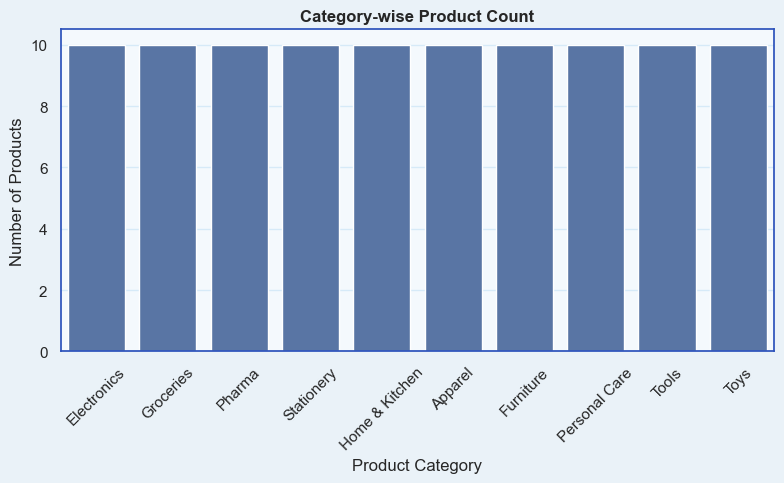

In [57]:
plt.figure(figsize=(8, 5))

sns.countplot(data=products_df, x="category")

plt.title("Category-wise Product Count")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [58]:
print(inventory_df)

    inventory_id  product_id   warehouse  stock_qty  reorder_level  \
0              1           1     Chennai         49             27   
1              2           2     Madurai         80            131   
2              3           3   Bangalore          5             68   
3              4           4   Bangalore        105             70   
4              5           5  Coimbatore        130             51   
..           ...         ...         ...        ...            ...   
95            96          96   Bangalore        101             40   
96            97          97     Chennai        314             79   
97            98          98     Madurai        139            139   
98            99          99  Coimbatore        435            108   
99           100         100      Trichy         49             97   

    safety_stock last_restock_date  
0              6        2026-09-25  
1             27        2026-08-05  
2             13        2026-08-03  
3          

C:\Users\acer\AppData\Local\Temp\ipykernel_72048\896821354.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


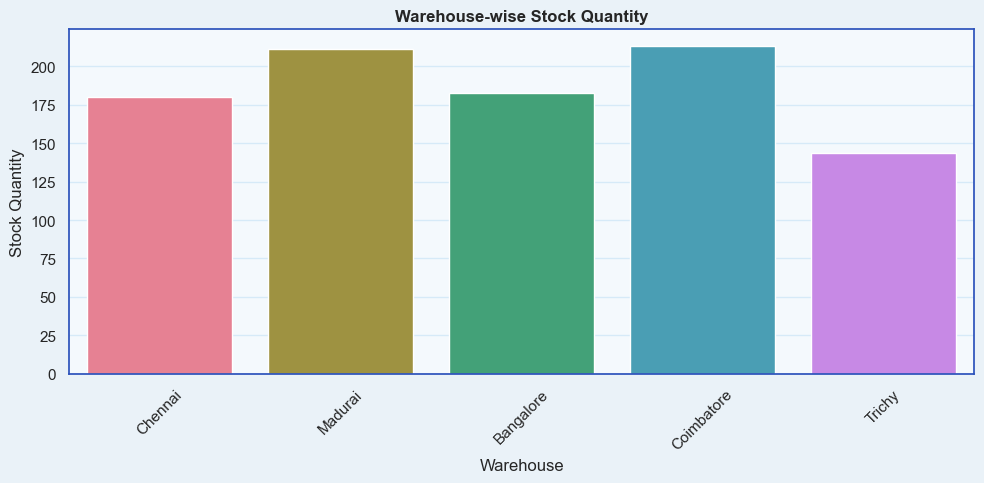

In [59]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=inventory_df,
    x="warehouse",
    y="stock_qty",
    palette="husl",
    errorbar=None
)

plt.title("Warehouse-wise Stock Quantity")
plt.xlabel("Warehouse")
plt.ylabel("Stock Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [60]:
print(sales_df)

    order_id  product_id  order_date  quantity      region order_status  \
0          1          74  2026-07-03        37  Coimbatore    Cancelled   
1          2          38  2026-01-12        54     Madurai    Delivered   
2          3           2  2026-01-26        59   Bangalore    Cancelled   
3          4          64  2026-05-27        50      Trichy      Pending   
4          5          46  2026-04-23        41      Trichy      Pending   
..       ...         ...         ...       ...         ...          ...   
95        96          99  2026-09-10        30   Bangalore      Pending   
96        97          58  2026-06-15        56  Coimbatore    Delivered   
97        98          57  2026-02-04        31     Madurai    Cancelled   
98        99          39  2026-05-21        38     Chennai    Delivered   
99       100          65  2026-02-07        20     Madurai      Shipped   

    total_amount  
0       97152.01  
1       16071.48  
2       59886.18  
3      130253.50  
4   

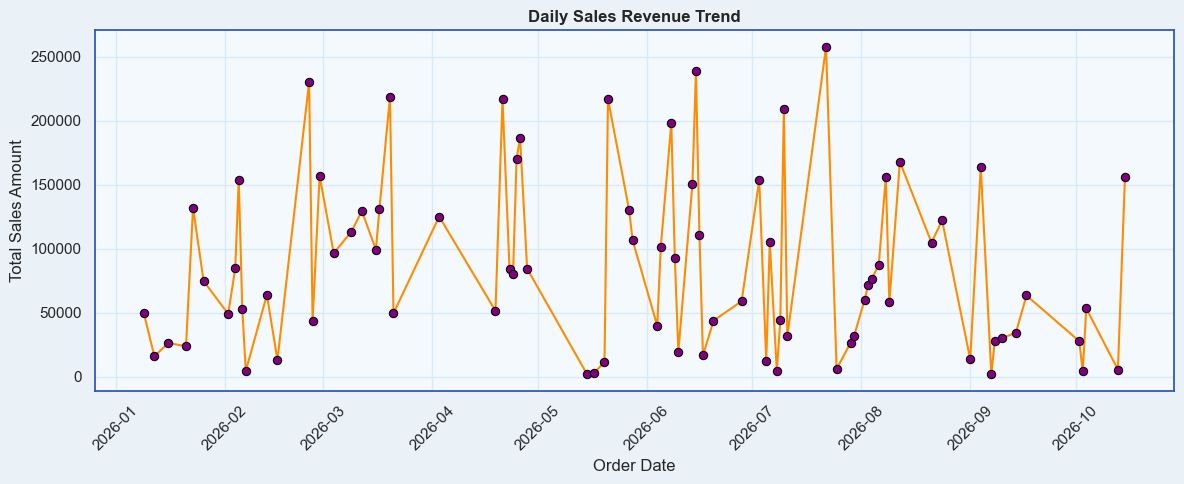

In [61]:
plt.figure(figsize=(12, 5))

sales_df["order_date"] = pd.to_datetime(sales_df["order_date"])

daily_sales = ( sales_df.groupby("order_date")["total_amount"].sum().reset_index())

sns.lineplot(
    data=daily_sales,
    x="order_date",
    y="total_amount",
    color="darkorange",
    marker="o",
    markerfacecolor="purple",
    markeredgecolor="black"
)

plt.title("Daily Sales Revenue Trend")
plt.xlabel("Order Date")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

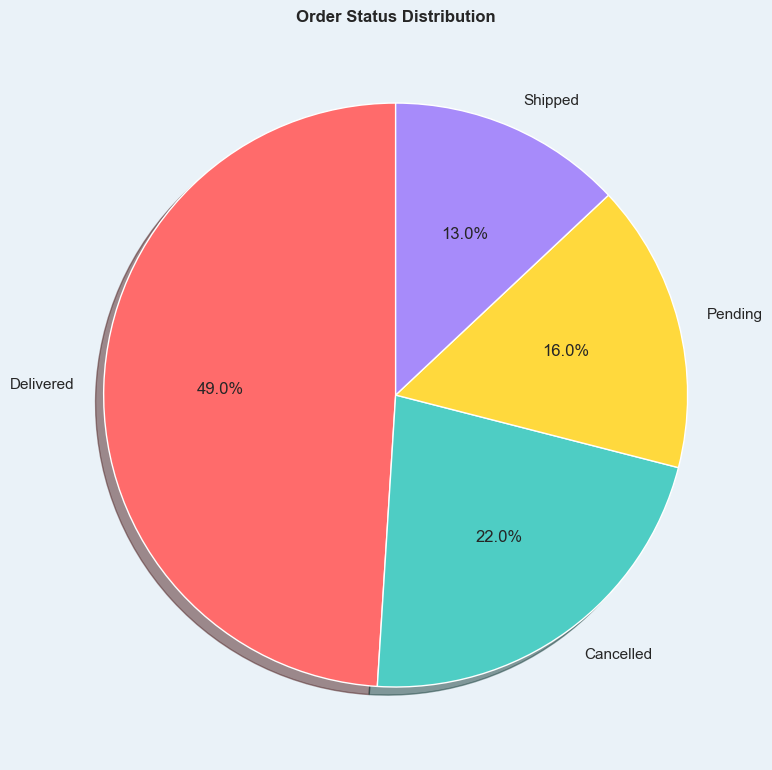

In [62]:
plt.figure(figsize=(8, 8))

status_counts = sales_df["order_status"].value_counts()

colors = ["#FF6B6B", "#4ECDC4", "#FFD93D", "#A78BFA"]

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    colors=colors,
    startangle=90,
    shadow=True
)

plt.title("Order Status Distribution")
plt.tight_layout()
plt.show()

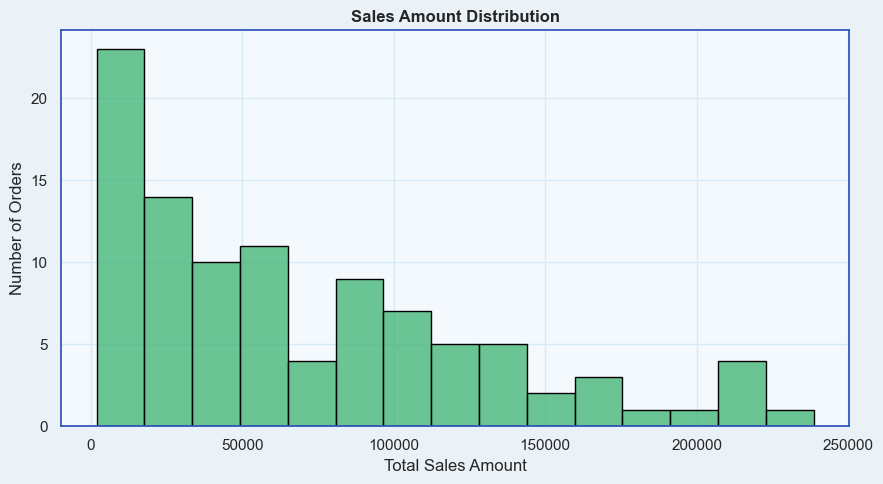

In [63]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=sales_df,
    x="total_amount",
    bins=15,
    color="mediumseagreen",
    edgecolor="black"
)

plt.title("Sales Amount Distribution")
plt.xlabel("Total Sales Amount")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

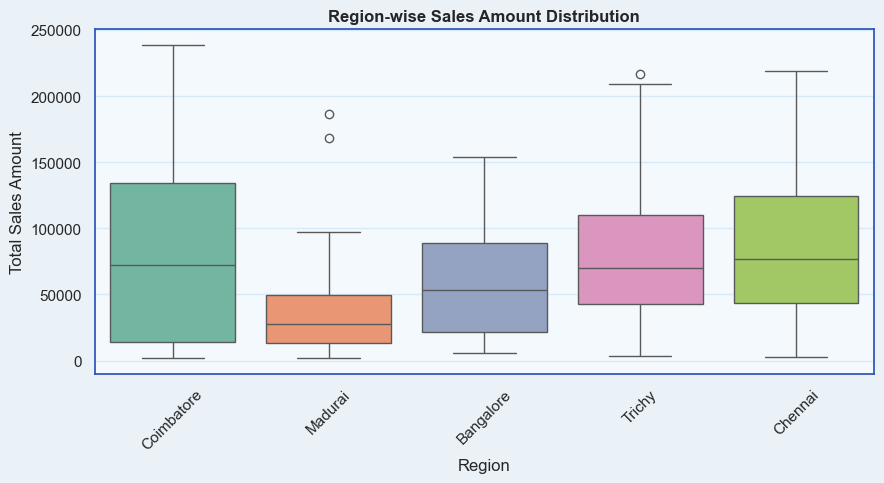

In [64]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sales_df,
    x="region",
    y="total_amount",
    hue="region",
    palette="Set2",
    legend=False
)

plt.title("Region-wise Sales Amount Distribution")
plt.xlabel("Region")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

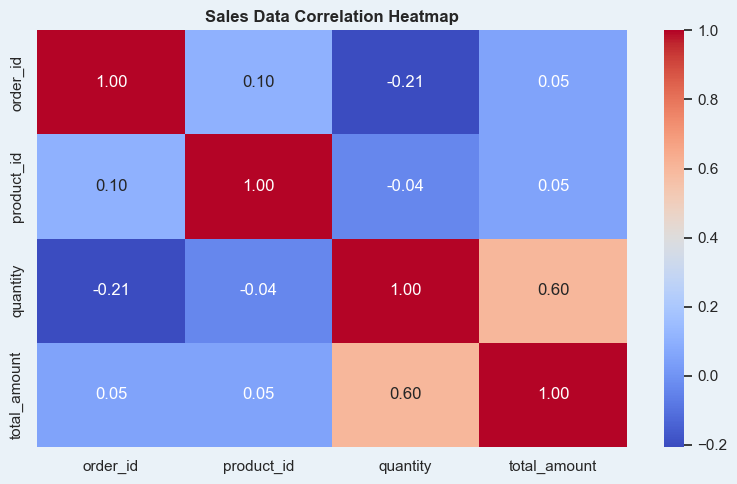

In [65]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    sales_df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Sales Data Correlation Heatmap")
plt.tight_layout()
plt.show()

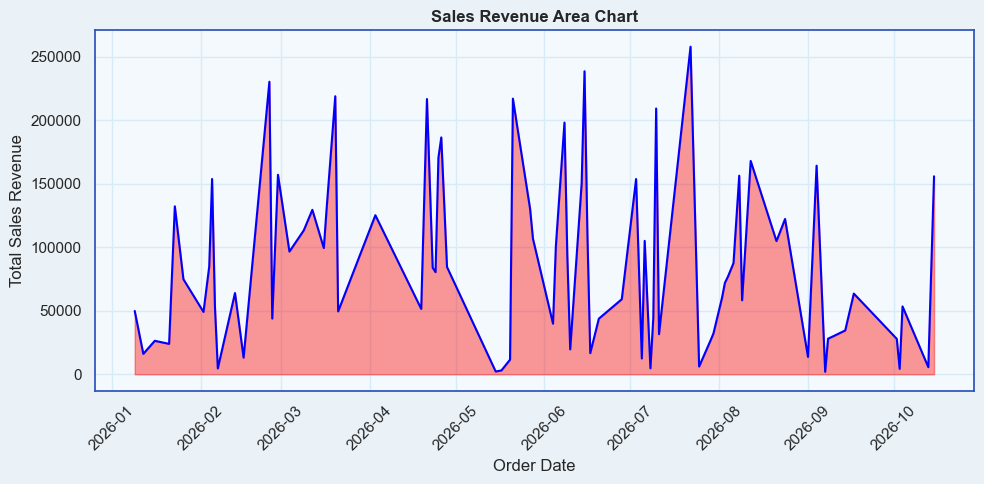

In [66]:
sales_trend = sales_df.groupby("order_date")["total_amount"].sum().sort_index()

plt.figure(figsize=(10, 5))

plt.fill_between(
    sales_trend.index,
    sales_trend.values,
    alpha=0.4,
    color="red"
)

plt.plot(sales_trend.index, sales_trend.values, color="blue")

plt.title("Sales Revenue Area Chart")
plt.xlabel("Order Date")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

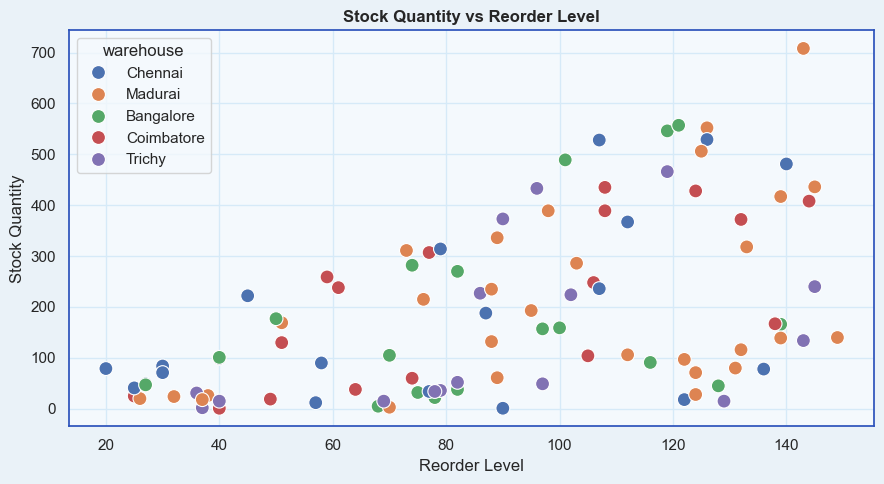

In [67]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=inventory_df,
    x="reorder_level",
    y="stock_qty",
    hue="warehouse",
    s=100
)

plt.title("Stock Quantity vs Reorder Level")
plt.xlabel("Reorder Level")
plt.ylabel("Stock Quantity")
plt.tight_layout()
plt.show()

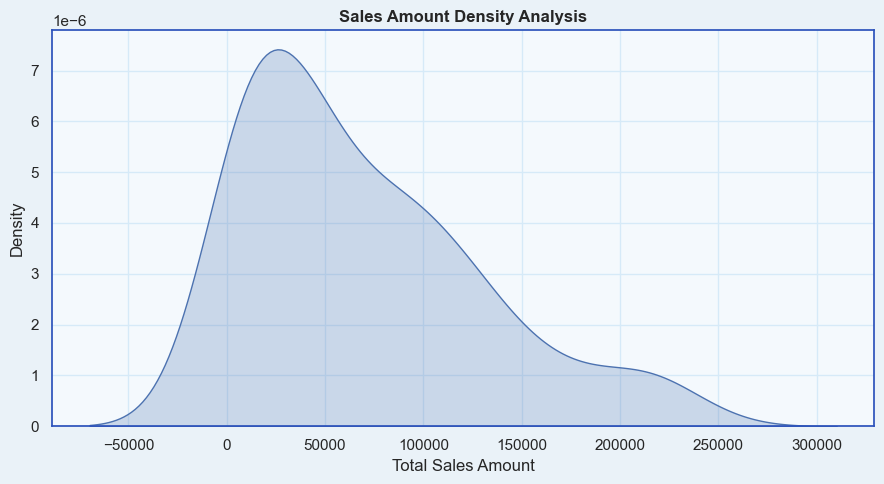

In [68]:
plt.figure(figsize=(9, 5))

sns.kdeplot(
    data=sales_df,
    x="total_amount",
    fill=True
)

plt.title("Sales Amount Density Analysis")
plt.xlabel("Total Sales Amount")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

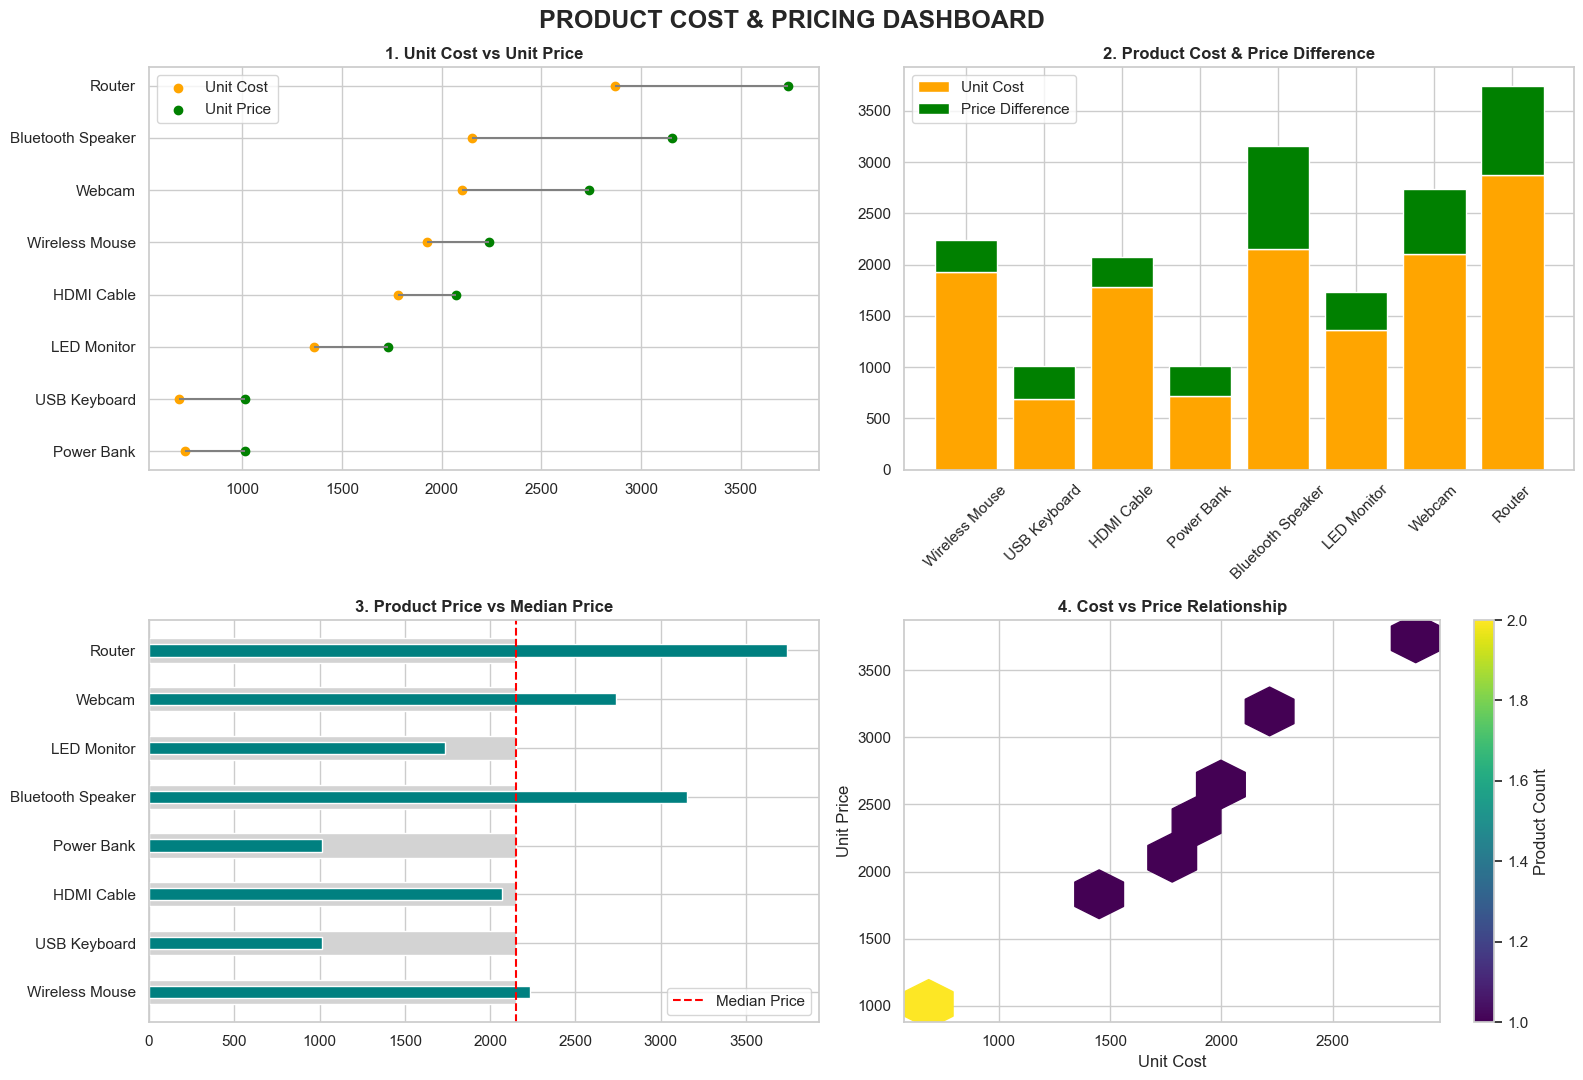

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = products_df.copy()
df.columns = df.columns.str.strip().str.lower()
for col in ["unit_cost", "unit_price", "lead_time_days"]:df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["unit_cost", "unit_price", "lead_time_days"])
df = df.head(8).reset_index(drop=True)
df["profit_margin"] = df["unit_price"] - df["unit_cost"]


fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Dumbbell Chart
data = df.sort_values("unit_price").reset_index(drop=True)
axes[0, 0].hlines(y=data["product_name"],xmin=data["unit_cost"],xmax=data["unit_price"],color="gray")
axes[0, 0].scatter(data["unit_cost"], data["product_name"],color="orange", label="Unit Cost")
axes[0, 0].scatter(data["unit_price"], data["product_name"],color="green", label="Unit Price")
axes[0, 0].set_title("1. Unit Cost vs Unit Price")
axes[0, 0].legend()

# 2. Cost & Price Difference
axes[0, 1].bar(df["product_name"],df["unit_cost"], color="orange",label="Unit Cost")
axes[0, 1].bar(df["product_name"],df["profit_margin"],bottom=df["unit_cost"],color="green",label="Price Difference")
axes[0, 1].set_title("2. Product Cost & Price Difference")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].legend()

# 3. Bullet-style Chart
target = df["unit_price"].median()
axes[1, 0].barh(df["product_name"],[target] * len(df),color="lightgray",height=0.5)
axes[1, 0].barh(df["product_name"],df["unit_price"],color="teal",height=0.25)
axes[1, 0].axvline(target, color="red", linestyle="--",label="Median Price")
axes[1, 0].set_title("3. Product Price vs Median Price")
axes[1, 0].legend()

# 4. Hexbin Chart
hex_chart = axes[1, 1].hexbin(df["unit_cost"],df["unit_price"],gridsize=10,cmap="viridis",mincnt=1)
fig.colorbar(hex_chart, ax=axes[1, 1], label="Product Count")
axes[1, 1].set_title("4. Cost vs Price Relationship")
axes[1, 1].set_xlabel("Unit Cost")
axes[1, 1].set_ylabel("Unit Price")
fig.suptitle("PRODUCT COST & PRICING DASHBOARD",fontsize=18,fontweight="bold")
plt.tight_layout()
plt.show()

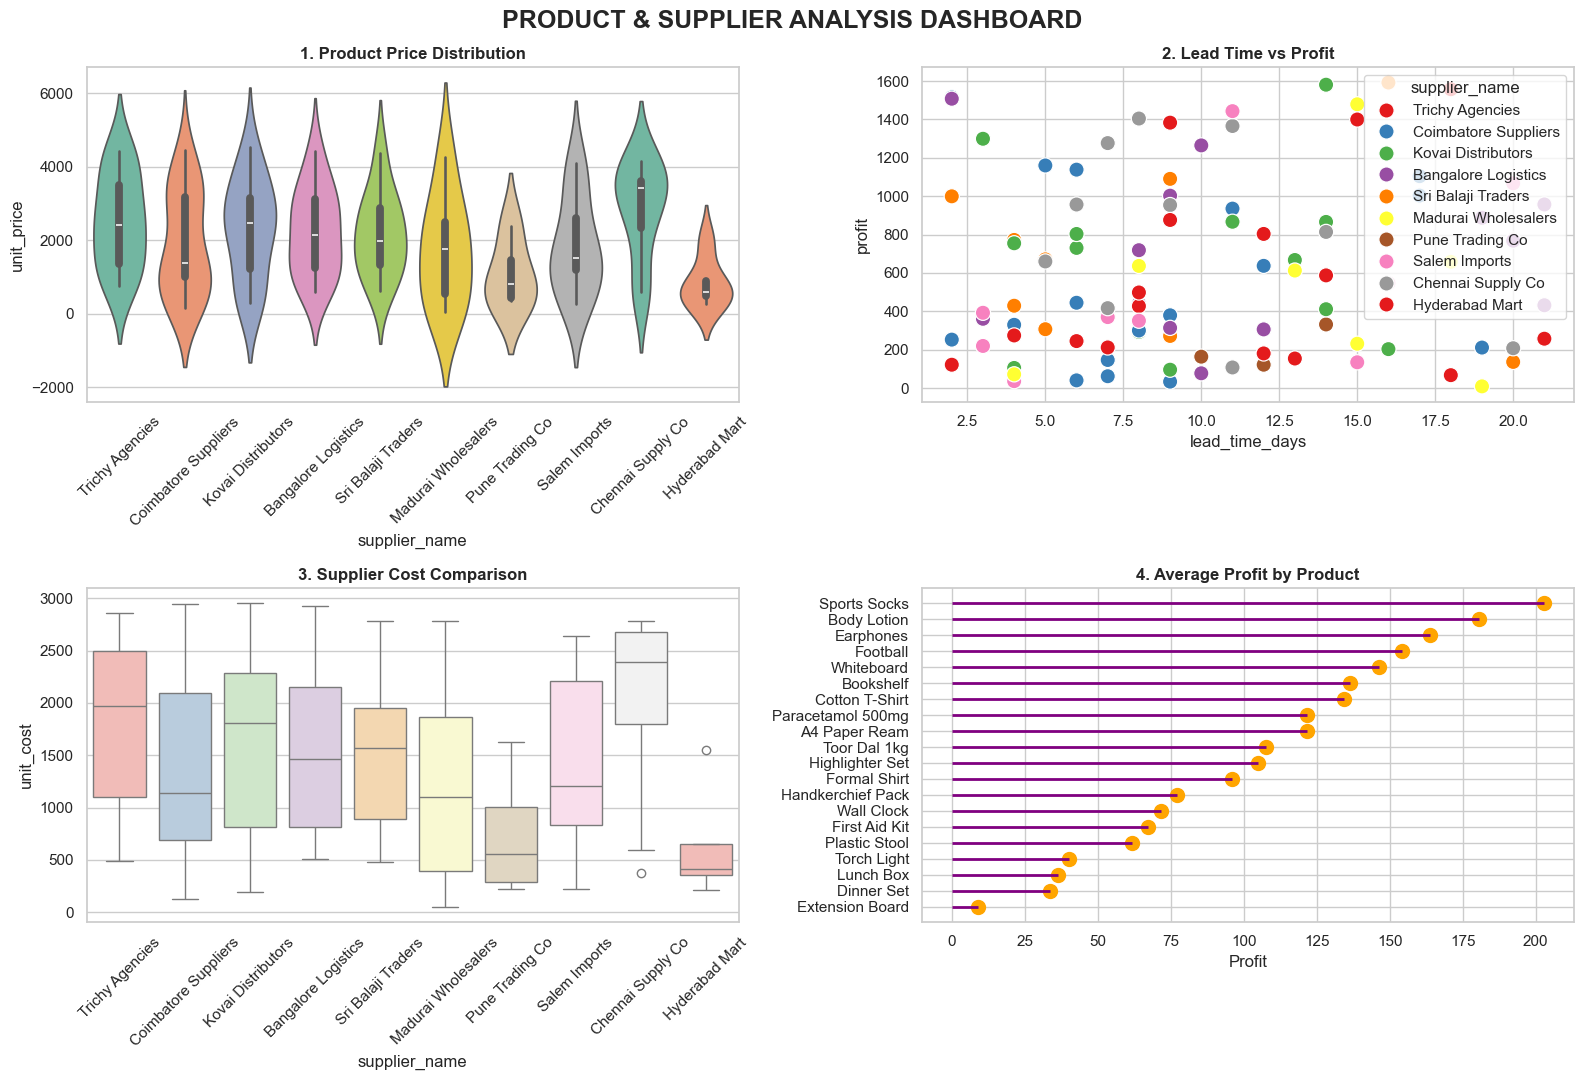

In [70]:
sns.set_theme(style="whitegrid")

df = products_df.copy()
df["unit_cost"] = pd.to_numeric(df["unit_cost"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["lead_time_days"] = pd.to_numeric(df["lead_time_days"], errors="coerce")
df = df.dropna(subset=[ "product_name", "supplier_name","unit_cost", "unit_price", "lead_time_days"])
df["profit"] = df["unit_price"] - df["unit_cost"]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Violin Plot – Product Price Distribution
sns.violinplot(data=df, x="supplier_name", y="unit_price", hue="supplier_name", palette="Set2", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("1. Product Price Distribution")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Scatter Plot – Lead Time vs Profit
sns.scatterplot(data=df,x="lead_time_days",y="profit",hue="supplier_name",s=120,palette="Set1",ax=axes[0, 1])
axes[0, 1].set_title("2. Lead Time vs Profit")

# 3. Box Plot – Supplier Unit Cost
sns.boxplot(data=df,x="supplier_name",y="unit_cost",hue="supplier_name",palette="Pastel1",legend=False,ax=axes[1, 0])
axes[1, 0].set_title("3. Supplier Cost Comparison")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Lollipop Chart – Profit by Product
profit_data = df.groupby("product_name")["profit"].mean().sort_values().head(20)
axes[1, 1].hlines(y=profit_data.index,xmin=0,xmax=profit_data.values,color="purple",linewidth=2)
axes[1, 1].scatter(profit_data.values,profit_data.index,color="orange",s=100)
axes[1, 1].set_title("4. Average Profit by Product")
axes[1, 1].set_xlabel("Profit")
fig.suptitle("PRODUCT & SUPPLIER ANALYSIS DASHBOARD",fontsize=18,fontweight="bold")

plt.tight_layout()
plt.show()